In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:

import pandas as pd

df = pd.read_csv("used_cars_dataset.csv")

df.head()


,listing_id,brand,model,year,mileage_km,transmission,fuel_type,engine_cc,body_type,color,city,seller_type,accident_history,previous_owners,condition_rating,photos_count,price_egp,sold_within_30_days
0,CAR-52762,MG,ZS,2021,64900.0,Automatic,Diesel,1500.0,SUV,Black,Giza,Individual,No,1.0,Fair,8.0,655000,Yes
1,CAR-52678,Kia,Cerato,2023,NaN,Automatic,Diesel,1600.0,Sedan,Grey,Giza,Individual,No,1.0,Good,12.0,1012000,No
2,CAR-52822,Skoda,Octavia,2009,224500.0,Automatic,Petrol,1400.0,Sedan,Silver,Banha,Dealer,Yes,2.0,Fair,11.0,229000,No
3,CAR-51133,Fiat,Tipo,2019,103800.0,Automatic,Petrol,1600.0,Sedan,Silver,ALEXANDRIA,Individual,No,2.0,Fair,7.0,319000,No
4,CAR-51465,Mitsubishi,Lancer,2022,50200.0,Manual,Hybrid,1600.0,Sedan,White,Cairo,Individual,No,NaN,Fair,8.0,425000,No


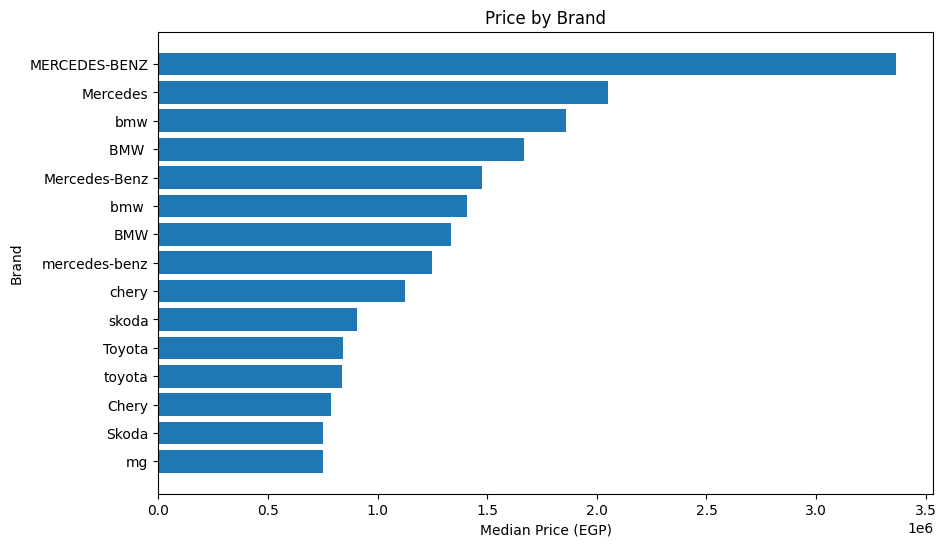

In [ ]:

brand_prices = df.groupby("brand")["price_egp"].median()
brand_prices = brand_prices.sort_values().tail(15)
plt.figure(figsize=(10, 6))
plt.barh(brand_prices.index, brand_prices.values)
plt.title("Price by Brand")
plt.xlabel("Median Price (EGP)")
plt.ylabel("Brand")

plt.show()


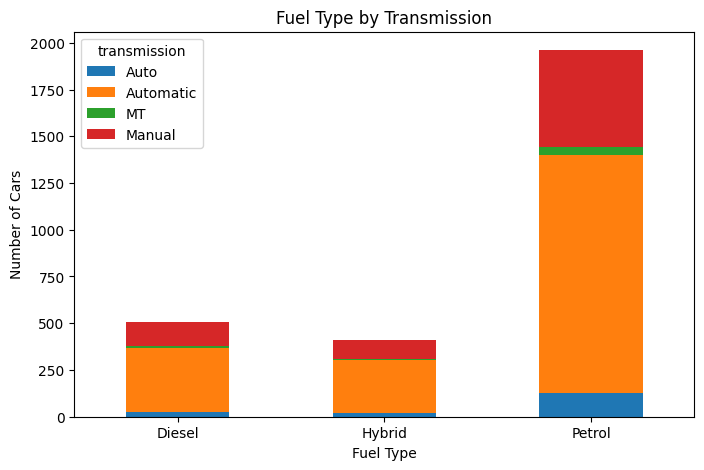

In [14]:

fuel = pd.crosstab(df["fuel_type"], df["transmission"])
fuel.plot(kind="bar", stacked=True, figsize=(8, 5))
plt.title("Fuel Type by Transmission")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Cars")
plt.xticks(rotation=0)
plt.show()


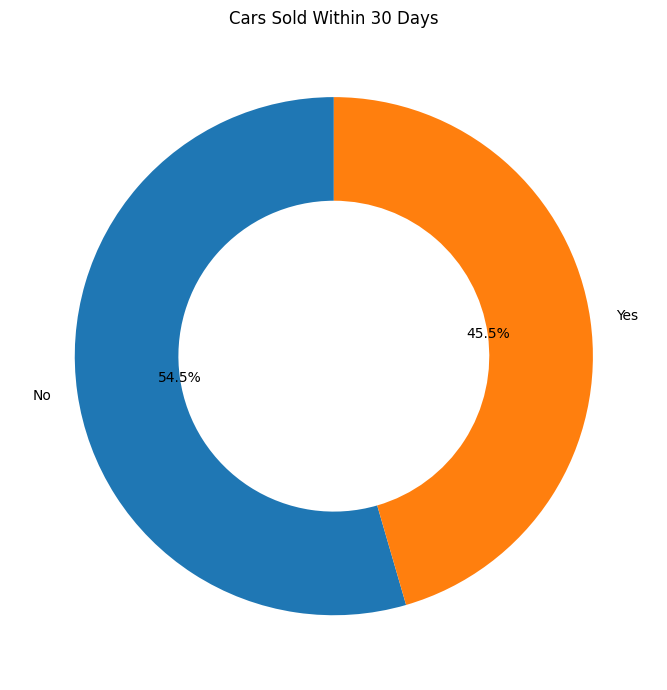

In [15]:

sales_counts = df["sold_within_30_days"].value_counts().dropna()
plt.figure(figsize=(7, 7))
plt.pie(
    sales_counts.values,
    labels=sales_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"width": 0.4}
)
plt.title("Cars Sold Within 30 Days")
plt.tight_layout()
plt.show()


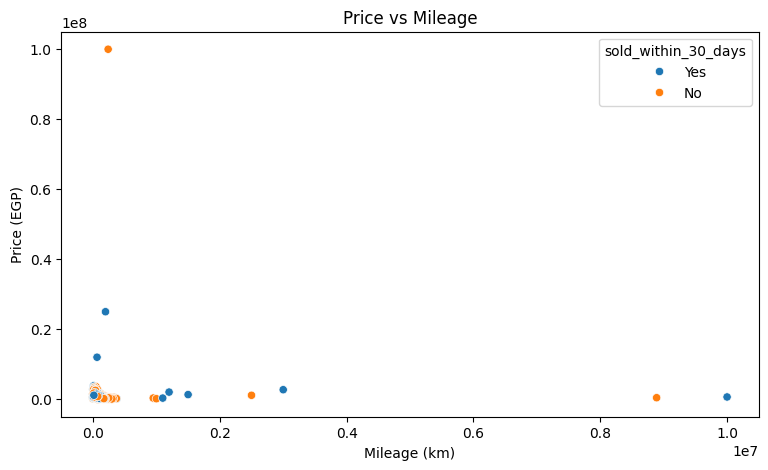

In [16]:

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df,
    x="mileage_km",
    y="price_egp",
    hue="sold_within_30_days"
)
plt.title("Price vs Mileage")
plt.xlabel("Mileage (km)")
plt.ylabel("Price (EGP)")
plt.show()


In [10]:

%pip install plotly


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:

import plotly.express as px


In [12]:

fig = px.scatter_3d(
    df,
    x="year",
    y="mileage_km",
    z="price_egp",
    color="sold_within_30_days",
    hover_data=["brand", "model", "city"],
    title="3D Visualization: Car Year, Mileage and Price",
    labels={
        "year": "Manufacturing Year",
        "mileage_km": "Mileage (km)",
        "price_egp": "Price (EGP)",
        "sold_within_30_days": "Sold Within 30 Days"
    },
    opacity=0.7
)
fig.update_traces(marker=dict(size=4))

fig.update_layout(
    width=1000,
    height=750,
    scene=dict(
        xaxis_title="Manufacturing Year",
        yaxis_title="Mileage (km)",
        zaxis_title="Price (EGP)",
        aspectmode="auto"
    )
)

fig.show()
